# Milestone One: Additional Analyses and Model Verification

This notebook performs supplementary analyses for the Module C Milestone One report.

The purpose is to:

1. verify class distributions and evaluation baselines;
2. reproduce final Week 4-6 models using the hyperparameters already selected in the weekly notebooks;
3. compare the final classification models on a common evaluation framework;
4. investigate the effect of classification threshold selection on the imbalanced Framingham outcome;
5. quantify uncertainty in model performance using paired bootstrap resampling; and
6. generate publication-quality figures for the Milestone One report.

The original Week 1-6 notebooks remain unchanged. Hyperparameters previously selected using cross-validation are reused here rather than repeating expensive hyperparameter searches.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict
)

from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries loaded successfully.")

Libraries loaded successfully.


## Load the Project Datasets

The analysis continues using the same preprocessed Statlog Heart Disease and Framingham Heart Study datasets used throughout Weeks 1-6.

In [1]:
from google.colab import files

uploaded = files.upload()

Saving preprocessed_framingham.csv to preprocessed_framingham.csv
Saving preprocessed_heart_disease.csv to preprocessed_heart_disease.csv


In [4]:
heart = pd.read_csv(
    "/content/preprocessed_heart_disease.csv"
)

framingham = pd.read_csv(
    "/content/preprocessed_framingham.csv"
)

print("Statlog shape:", heart.shape)
print("Framingham shape:", framingham.shape)

display(heart.head())
display(framingham.head())

Statlog shape: (270, 14)
Framingham shape: (4238, 16)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,70,1,3,130,322,0,2,109,0,2.4,1,3,1,1
1,67,0,2,115,564,0,2,160,0,1.6,1,0,3,0
2,57,1,1,124,261,0,0,141,0,0.3,0,0,3,1
3,64,1,3,128,263,0,0,105,1,0.2,1,1,3,0
4,74,0,1,120,269,0,2,121,1,0.2,0,1,1,0


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


## Predictor Definitions

The same predictor groups used in Weeks 4-6 are retained so that the supplementary analyses remain directly comparable to the original classification models.

In [5]:
# -----------------------------
# STATLOG
# -----------------------------

heart_numeric_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

heart_binary_features = [
    "sex",
    "fbs",
    "exang"
]

heart_categorical_features = [
    "cp",
    "restecg",
    "slope",
    "ca",
    "thal"
]

heart_features = (
    heart_numeric_features
    + heart_binary_features
    + heart_categorical_features
)


# -----------------------------
# FRAMINGHAM
# -----------------------------

framingham_numeric_features = [
    "age",
    "cigsPerDay",
    "totChol",
    "sysBP",
    "diaBP",
    "BMI",
    "heartRate",
    "glucose"
]

framingham_binary_features = [
    "male",
    "currentSmoker",
    "BPMeds",
    "prevalentStroke",
    "prevalentHyp",
    "diabetes"
]

framingham_categorical_features = [
    "education"
]

framingham_features = (
    framingham_numeric_features
    + framingham_binary_features
    + framingham_categorical_features
)

print("Statlog predictors:", len(heart_features))
print("Framingham predictors:", len(framingham_features))

Statlog predictors: 13
Framingham predictors: 15


## Reproduce the Original Train-Test Splits

The original classification notebooks used an 80/20 stratified train-test split with `random_state=42`.

The identical split is reproduced here so that supplementary analyses evaluate the same held-out observations as the Week 4-6 models.

In [6]:
# STATLOG

heart_model_data = heart[
    heart_features + ["target"]
].dropna()

X_heart = heart_model_data[
    heart_features
]

y_heart = heart_model_data[
    "target"
]

X_heart_train, X_heart_test, y_heart_train, y_heart_test = train_test_split(
    X_heart,
    y_heart,
    test_size=0.20,
    random_state=42,
    stratify=y_heart
)


# FRAMINGHAM

framingham_model_data = framingham[
    framingham_features + ["TenYearCHD"]
].dropna()

X_framingham = framingham_model_data[
    framingham_features
]

y_framingham = framingham_model_data[
    "TenYearCHD"
]

X_framingham_train, X_framingham_test, y_framingham_train, y_framingham_test = train_test_split(
    X_framingham,
    y_framingham,
    test_size=0.20,
    random_state=42,
    stratify=y_framingham
)

print("Statlog train:", X_heart_train.shape)
print("Statlog test:", X_heart_test.shape)

print("Framingham train:", X_framingham_train.shape)
print("Framingham test:", X_framingham_test.shape)

Statlog train: (216, 13)
Statlog test: (54, 13)
Framingham train: (3390, 15)
Framingham test: (848, 15)


## Class Distribution and Majority-Class Baseline

Because Framingham contains substantially fewer positive CHD cases than negative cases, raw accuracy can be misleading.

The class distribution and the accuracy obtainable by predicting the majority class for every observation are calculated below.

In [7]:
def summarize_classes(y, dataset_name):

    counts = y.value_counts().sort_index()
    percentages = (
        y.value_counts(normalize=True)
        .sort_index()
        * 100
    )

    result = pd.DataFrame({
        "Count": counts,
        "Percentage": percentages.round(2)
    })

    print(dataset_name)
    display(result)

    majority_accuracy = counts.max() / counts.sum()

    print(
        "Majority-class accuracy:",
        round(majority_accuracy, 3)
    )

    print()


summarize_classes(
    y_heart_test,
    "Statlog Test Set"
)

summarize_classes(
    y_framingham_test,
    "Framingham Test Set"
)

Statlog Test Set


,Count,Percentage
target,,
0,30,55.56
1,24,44.44


Majority-class accuracy: 0.556

Framingham Test Set


,Count,Percentage
TenYearCHD,,
0,719,84.79
1,129,15.21


Majority-class accuracy: 0.848



In [8]:
print(
    "Framingham training class counts:"
)

print(
    y_framingham_train.value_counts().sort_index()
)

negative_count = (
    y_framingham_train == 0
).sum()

positive_count = (
    y_framingham_train == 1
).sum()

print(
    "\nNegative-to-positive ratio:",
    round(
        negative_count / positive_count,
        2
    )
)

Framingham training class counts:
TenYearCHD
0    2875
1     515
Name: count, dtype: int64

Negative-to-positive ratio: 5.58


## Preprocessing Pipelines

Logistic regression and SVM use standardized continuous predictors because their estimation and regularization are affected by feature scale.

Decision trees and random forests do not require continuous-variable standardization, so their numerical predictors are passed through unchanged.

Categorical variables are one-hot encoded in both cases.

In [9]:
def create_scaled_preprocessor(
    numeric_features,
    binary_features,
    categorical_features
):

    return ColumnTransformer(
        transformers=[
            (
                "numeric",
                StandardScaler(),
                numeric_features
            ),
            (
                "binary",
                "passthrough",
                binary_features
            ),
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore"
                ),
                categorical_features
            )
        ]
    )


def create_tree_preprocessor(
    numeric_features,
    binary_features,
    categorical_features
):

    return ColumnTransformer(
        transformers=[
            (
                "numeric",
                "passthrough",
                numeric_features
            ),
            (
                "binary",
                "passthrough",
                binary_features
            ),
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore"
                ),
                categorical_features
            )
        ]
    )

## Refit the Previously Selected Final Models

The hyperparameters below were already selected through the original Week 4-6 cross-validation procedures.

The expensive searches are therefore not repeated. Each winning model is simply refit once on the complete training set so that additional comparisons can be performed.

In [10]:
# =====================================
# STATLOG FINAL MODELS
# =====================================

heart_logistic = Pipeline([
    (
        "preprocessing",
        create_scaled_preprocessor(
            heart_numeric_features,
            heart_binary_features,
            heart_categorical_features
        )
    ),
    (
        "model",
        LogisticRegression(
            C=1,
            class_weight="balanced",
            max_iter=5000
        )
    )
])


heart_svm = Pipeline([
    (
        "preprocessing",
        create_scaled_preprocessor(
            heart_numeric_features,
            heart_binary_features,
            heart_categorical_features
        )
    ),
    (
        "model",
        SVC(
            kernel="poly",
            degree=2,
            C=1,
            gamma="scale",
            coef0=0,
            class_weight="balanced"
        )
    )
])


heart_tree = Pipeline([
    (
        "preprocessing",
        create_tree_preprocessor(
            heart_numeric_features,
            heart_binary_features,
            heart_categorical_features
        )
    ),
    (
        "model",
        DecisionTreeClassifier(
            criterion="entropy",
            max_depth=3,
            min_samples_split=2,
            min_samples_leaf=10,
            class_weight=None,
            random_state=42
        )
    )
])


heart_forest = Pipeline([
    (
        "preprocessing",
        create_tree_preprocessor(
            heart_numeric_features,
            heart_binary_features,
            heart_categorical_features
        )
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=200,
            criterion="entropy",
            max_depth=5,
            min_samples_split=10,
            min_samples_leaf=10,
            max_features="sqrt",
            class_weight=None,
            bootstrap=True,
            random_state=42,
            n_jobs=-1
        )
    )
])


# =====================================
# FRAMINGHAM FINAL MODELS
# =====================================

framingham_logistic = Pipeline([
    (
        "preprocessing",
        create_scaled_preprocessor(
            framingham_numeric_features,
            framingham_binary_features,
            framingham_categorical_features
        )
    ),
    (
        "model",
        LogisticRegression(
            C=0.01,
            class_weight="balanced",
            max_iter=5000
        )
    )
])


framingham_svm = Pipeline([
    (
        "preprocessing",
        create_scaled_preprocessor(
            framingham_numeric_features,
            framingham_binary_features,
            framingham_categorical_features
        )
    ),
    (
        "model",
        SVC(
            kernel="poly",
            degree=2,
            C=0.1,
            gamma="scale",
            coef0=0,
            class_weight="balanced"
        )
    )
])


framingham_tree = Pipeline([
    (
        "preprocessing",
        create_tree_preprocessor(
            framingham_numeric_features,
            framingham_binary_features,
            framingham_categorical_features
        )
    ),
    (
        "model",
        DecisionTreeClassifier(
            criterion="entropy",
            max_depth=2,
            min_samples_split=2,
            min_samples_leaf=1,
            class_weight="balanced",
            random_state=42
        )
    )
])


framingham_forest = Pipeline([
    (
        "preprocessing",
        create_tree_preprocessor(
            framingham_numeric_features,
            framingham_binary_features,
            framingham_categorical_features
        )
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=200,
            criterion="entropy",
            max_depth=5,
            min_samples_split=10,
            min_samples_leaf=1,
            max_features="sqrt",
            class_weight="balanced",
            bootstrap=True,
            random_state=42,
            n_jobs=-1
        )
    )
])

print("Final model definitions created.")

Final model definitions created.


In [11]:
heart_logistic.fit(
    X_heart_train,
    y_heart_train
)

heart_svm.fit(
    X_heart_train,
    y_heart_train
)

heart_tree.fit(
    X_heart_train,
    y_heart_train
)

heart_forest.fit(
    X_heart_train,
    y_heart_train
)


framingham_logistic.fit(
    X_framingham_train,
    y_framingham_train
)

framingham_svm.fit(
    X_framingham_train,
    y_framingham_train
)

framingham_tree.fit(
    X_framingham_train,
    y_framingham_train
)

framingham_forest.fit(
    X_framingham_train,
    y_framingham_train
)

print("All eight final models fitted.")

All eight final models fitted.


## Final Classification Model Comparison

The final logistic regression, SVM, decision tree, and random forest models are evaluated on the same held-out test observations.

This provides a direct comparison among the classification approaches from Weeks 4-6.

In [12]:
def evaluate_model(
    model,
    X_test,
    y_test,
    dataset,
    model_name
):

    predictions = model.predict(
        X_test
    )

    if hasattr(
        model.named_steps["model"],
        "predict_proba"
    ):

        scores = model.predict_proba(
            X_test
        )[:, 1]

    else:

        scores = model.decision_function(
            X_test
        )

    return {
        "Dataset": dataset,
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "F1": f1_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "ROC AUC": roc_auc_score(
            y_test,
            scores
        )
    }


classification_results = pd.DataFrame([

    evaluate_model(
        heart_logistic,
        X_heart_test,
        y_heart_test,
        "Statlog",
        "Logistic Regression"
    ),

    evaluate_model(
        heart_svm,
        X_heart_test,
        y_heart_test,
        "Statlog",
        "SVM"
    ),

    evaluate_model(
        heart_tree,
        X_heart_test,
        y_heart_test,
        "Statlog",
        "Decision Tree"
    ),

    evaluate_model(
        heart_forest,
        X_heart_test,
        y_heart_test,
        "Statlog",
        "Random Forest"
    ),

    evaluate_model(
        framingham_logistic,
        X_framingham_test,
        y_framingham_test,
        "Framingham",
        "Logistic Regression"
    ),

    evaluate_model(
        framingham_svm,
        X_framingham_test,
        y_framingham_test,
        "Framingham",
        "SVM"
    ),

    evaluate_model(
        framingham_tree,
        X_framingham_test,
        y_framingham_test,
        "Framingham",
        "Decision Tree"
    ),

    evaluate_model(
        framingham_forest,
        X_framingham_test,
        y_framingham_test,
        "Framingham",
        "Random Forest"
    )
])

classification_results = classification_results.round(
    3
)

display(
    classification_results
)

,Dataset,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Statlog,Logistic Regression,0.870,0.815,0.917,0.863,0.914
1,Statlog,SVM,0.815,0.750,0.875,0.808,0.899
2,Statlog,Decision Tree,0.852,0.808,0.875,0.840,0.835
3,Statlog,Random Forest,0.833,0.800,0.833,0.816,0.896
4,Framingham,Logistic Regression,0.667,0.254,0.612,0.359,0.695
5,Framingham,SVM,0.722,0.256,0.434,0.322,0.691
6,Framingham,Decision Tree,0.557,0.207,0.674,0.316,0.633
7,Framingham,Random Forest,0.696,0.245,0.481,0.325,0.680


## Threshold Analysis for Framingham Logistic Regression

The original Framingham logistic regression model had moderate ROC AUC but extremely poor recall at the default probability threshold of 0.50.

This analysis tests whether selecting a classification threshold using cross-validated training predictions can improve minority-class F1 without changing the underlying ordinary logistic regression model.

The threshold is selected entirely from out-of-fold predictions on the training data. The held-out test set is used only after threshold selection.

In [13]:
baseline_framingham_logistic = Pipeline([
    (
        "preprocessing",
        create_scaled_preprocessor(
            framingham_numeric_features,
            framingham_binary_features,
            framingham_categorical_features
        )
    ),
    (
        "model",
        LogisticRegression(
            C=1,
            class_weight=None,
            max_iter=5000
        )
    )
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_probabilities = cross_val_predict(
    baseline_framingham_logistic,
    X_framingham_train,
    y_framingham_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

thresholds = np.linspace(
    0.05,
    0.95,
    181
)

threshold_results = []

for threshold in thresholds:

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "F1": f1_score(
            y_framingham_train,
            predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_framingham_train,
            predictions,
            zero_division=0
        ),
        "Precision": precision_score(
            y_framingham_train,
            predictions,
            zero_division=0
        )
    })

threshold_results = pd.DataFrame(
    threshold_results
)

best_row = threshold_results.loc[
    threshold_results["F1"].idxmax()
]

best_threshold = best_row[
    "Threshold"
]

print(
    "Best CV-selected threshold:",
    round(best_threshold, 3)
)

display(
    best_row.to_frame().T.round(3)
)

Best CV-selected threshold: 0.18


,Threshold,F1,Recall,Precision
26,0.18,0.395,0.588,0.297


In [14]:
baseline_framingham_logistic.fit(
    X_framingham_train,
    y_framingham_train
)

baseline_test_probabilities = (
    baseline_framingham_logistic.predict_proba(
        X_framingham_test
    )[:, 1]
)

default_predictions = (
    baseline_test_probabilities >= 0.50
).astype(int)

threshold_predictions = (
    baseline_test_probabilities >= best_threshold
).astype(int)

tuned_predictions = framingham_logistic.predict(
    X_framingham_test
)


threshold_comparison = pd.DataFrame([

    {
        "Strategy":
            "Ordinary Logistic, threshold 0.50",

        "Accuracy":
            accuracy_score(
                y_framingham_test,
                default_predictions
            ),

        "Precision":
            precision_score(
                y_framingham_test,
                default_predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_framingham_test,
                default_predictions,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_framingham_test,
                default_predictions,
                zero_division=0
            ),

        "Predicted Positives":
            default_predictions.sum()
    },

    {
        "Strategy":
            "Ordinary Logistic, CV-selected threshold",

        "Accuracy":
            accuracy_score(
                y_framingham_test,
                threshold_predictions
            ),

        "Precision":
            precision_score(
                y_framingham_test,
                threshold_predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_framingham_test,
                threshold_predictions,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_framingham_test,
                threshold_predictions,
                zero_division=0
            ),

        "Predicted Positives":
            threshold_predictions.sum()
    },

    {
        "Strategy":
            "Balanced Tuned Logistic",

        "Accuracy":
            accuracy_score(
                y_framingham_test,
                tuned_predictions
            ),

        "Precision":
            precision_score(
                y_framingham_test,
                tuned_predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_framingham_test,
                tuned_predictions,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_framingham_test,
                tuned_predictions,
                zero_division=0
            ),

        "Predicted Positives":
            tuned_predictions.sum()
    }
]).round(3)

display(
    threshold_comparison
)

,Strategy,Accuracy,Precision,Recall,F1,Predicted Positives
0,"Ordinary Logistic, threshold 0.50",0.844,0.421,0.062,0.108,19
1,"Ordinary Logistic, CV-selected threshold",0.713,0.258,0.473,0.334,236
2,Balanced Tuned Logistic,0.667,0.254,0.612,0.359,311


### Threshold Analysis Interpretation

The ordinary Framingham logistic regression performed poorly at the conventional 0.50 classification threshold, identifying only 6.2% of positive CHD cases.

Using five-fold out-of-fold predictions from the training data, a threshold of 0.18 maximized F1. Applying this threshold to the held-out test set increased recall from 0.062 to 0.473 and F1 from 0.108 to 0.334, although accuracy declined from 0.844 to 0.713.

The fully tuned balanced logistic model increased recall further to 0.612 and F1 to 0.359, while precision remained nearly unchanged relative to the threshold-adjusted ordinary model.

Therefore, much of the original improvement in minority-class detection can be explained by changing the decision threshold rather than by obtaining substantially better ranking discrimination. The tuned model nevertheless produced an additional increase in recall. Because the tuned model changed both class weighting and regularization strength, this remaining difference cannot be attributed to either change individually.

This result also explains why raw accuracy was misleading for Framingham. The majority-class baseline already achieves approximately 0.848 accuracy while identifying no positive CHD cases.

## Bootstrap Uncertainty of Test Performance

Because all final models are evaluated on the same held-out patients, differences among models can be assessed using paired bootstrap resampling.

The same test observations are resampled for all models in each bootstrap iteration. This preserves the paired nature of the comparison.

Bootstrap confidence intervals are estimated for ROC AUC and F1 score.

In [15]:
def get_predictions_and_scores(
    model,
    X_test
):

    predictions = model.predict(
        X_test
    )

    if hasattr(
        model.named_steps["model"],
        "predict_proba"
    ):

        scores = model.predict_proba(
            X_test
        )[:, 1]

    else:

        scores = model.decision_function(
            X_test
        )

    return (
        np.asarray(predictions),
        np.asarray(scores)
    )


framingham_model_outputs = {}

for name, model in {

    "Logistic Regression":
        framingham_logistic,

    "SVM":
        framingham_svm,

    "Decision Tree":
        framingham_tree,

    "Random Forest":
        framingham_forest

}.items():

    framingham_model_outputs[name] = (
        get_predictions_and_scores(
            model,
            X_framingham_test
        )
    )

In [16]:
def bootstrap_metric_ci(
    y_true,
    predictions,
    scores,
    n_bootstrap=2000,
    random_state=42
):

    rng = np.random.default_rng(
        random_state
    )

    y_true = np.asarray(
        y_true
    )

    predictions = np.asarray(
        predictions
    )

    scores = np.asarray(
        scores
    )

    n = len(
        y_true
    )

    auc_values = []
    f1_values = []

    for _ in range(
        n_bootstrap
    ):

        indices = rng.integers(
            0,
            n,
            n
        )

        y_sample = y_true[
            indices
        ]

        # ROC AUC cannot be calculated
        # if a resample contains only one class.
        if len(
            np.unique(
                y_sample
            )
        ) < 2:

            continue

        auc_values.append(
            roc_auc_score(
                y_sample,
                scores[indices]
            )
        )

        f1_values.append(
            f1_score(
                y_sample,
                predictions[indices],
                zero_division=0
            )
        )

    return {

        "AUC Lower":
            np.percentile(
                auc_values,
                2.5
            ),

        "AUC Upper":
            np.percentile(
                auc_values,
                97.5
            ),

        "F1 Lower":
            np.percentile(
                f1_values,
                2.5
            ),

        "F1 Upper":
            np.percentile(
                f1_values,
                97.5
            )
    }


bootstrap_rows = []

for model_name, (
    predictions,
    scores
) in framingham_model_outputs.items():

    ci = bootstrap_metric_ci(
        y_framingham_test,
        predictions,
        scores
    )

    bootstrap_rows.append({
        "Model":
            model_name,

        **ci
    })

framingham_bootstrap_ci = pd.DataFrame(
    bootstrap_rows
).round(3)

display(
    framingham_bootstrap_ci
)

,Model,AUC Lower,AUC Upper,F1 Lower,F1 Upper
0,Logistic Regression,0.651,0.741,0.302,0.420
1,SVM,0.645,0.738,0.261,0.385
2,Decision Tree,0.585,0.681,0.268,0.366
3,Random Forest,0.633,0.727,0.266,0.384


In [17]:
def paired_bootstrap_difference(
    y_true,
    pred_a,
    score_a,
    pred_b,
    score_b,
    n_bootstrap=2000,
    random_state=42
):

    rng = np.random.default_rng(
        random_state
    )

    y_true = np.asarray(
        y_true
    )

    n = len(
        y_true
    )

    auc_differences = []
    f1_differences = []

    for _ in range(
        n_bootstrap
    ):

        indices = rng.integers(
            0,
            n,
            n
        )

        y_sample = y_true[
            indices
        ]

        if len(
            np.unique(
                y_sample
            )
        ) < 2:

            continue

        auc_a = roc_auc_score(
            y_sample,
            score_a[indices]
        )

        auc_b = roc_auc_score(
            y_sample,
            score_b[indices]
        )

        f1_a = f1_score(
            y_sample,
            pred_a[indices],
            zero_division=0
        )

        f1_b = f1_score(
            y_sample,
            pred_b[indices],
            zero_division=0
        )

        auc_differences.append(
            auc_a - auc_b
        )

        f1_differences.append(
            f1_a - f1_b
        )

    return {

        "AUC Difference":
            np.mean(
                auc_differences
            ),

        "AUC Difference Lower":
            np.percentile(
                auc_differences,
                2.5
            ),

        "AUC Difference Upper":
            np.percentile(
                auc_differences,
                97.5
            ),

        "F1 Difference":
            np.mean(
                f1_differences
            ),

        "F1 Difference Lower":
            np.percentile(
                f1_differences,
                2.5
            ),

        "F1 Difference Upper":
            np.percentile(
                f1_differences,
                97.5
            )
    }

In [18]:
logistic_pred, logistic_score = (
    framingham_model_outputs[
        "Logistic Regression"
    ]
)

difference_rows = []

for other_model in [
    "SVM",
    "Decision Tree",
    "Random Forest"
]:

    other_pred, other_score = (
        framingham_model_outputs[
            other_model
        ]
    )

    result = paired_bootstrap_difference(
        y_framingham_test,
        logistic_pred,
        logistic_score,
        other_pred,
        other_score
    )

    difference_rows.append({
        "Comparison":
            f"Logistic minus {other_model}",

        **result
    })


paired_differences = pd.DataFrame(
    difference_rows
).round(3)

display(
    paired_differences
)

,Comparison,AUC Difference,AUC Difference Lower,AUC Difference Upper,F1 Difference,F1 Difference Lower,F1 Difference Upper
0,Logistic minus SVM,0.004,-0.013,0.021,0.038,-0.004,0.081
1,Logistic minus Decision Tree,0.061,0.025,0.098,0.042,0.002,0.084
2,Logistic minus Random Forest,0.015,-0.003,0.033,0.035,-0.006,0.076


### Bootstrap Interpretation

Bootstrap resampling shows that several apparent differences among the Framingham models are small relative to uncertainty in the held-out test sample.

The logistic regression model had slightly higher point estimates for ROC AUC and F1 than the SVM and random forest. However, the paired 95% bootstrap confidence intervals for both differences included zero. Therefore, the available test data do not provide strong evidence that logistic regression meaningfully outperformed either of these models.

In contrast, the paired comparison between logistic regression and the decision tree produced confidence intervals above zero for both ROC AUC and F1. This provides stronger evidence that logistic regression generalized better than the single decision tree on the Framingham test set.

These intervals quantify sampling uncertainty conditional on the already-trained models. They do not capture additional uncertainty that would arise from repeating the complete training and hyperparameter-selection process on a different dataset.

## Publication-Quality Framingham Logistic Confusion Matrices

The original and tuned Framingham logistic classifiers are compared using the same held-out test observations.

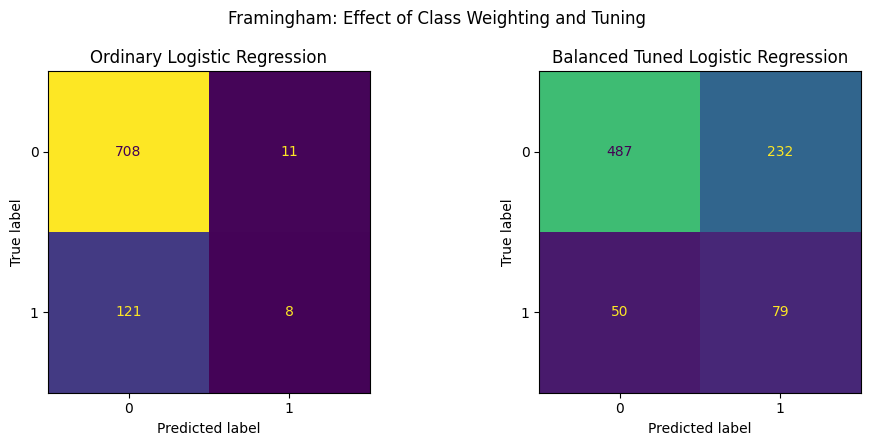

In [23]:
ordinary_cm = confusion_matrix(
    y_framingham_test,
    default_predictions
)

tuned_cm = confusion_matrix(
    y_framingham_test,
    tuned_predictions
)

shared_max = max(
    ordinary_cm.max(),
    tuned_cm.max()
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4.5)
)

ConfusionMatrixDisplay(
    confusion_matrix=ordinary_cm,
    display_labels=[0, 1]
).plot(
    ax=axes[0],
    colorbar=False,
    im_kw={
        "vmin": 0,
        "vmax": shared_max
    }
)

axes[0].set_title(
    "Ordinary Logistic Regression"
)


ConfusionMatrixDisplay(
    confusion_matrix=tuned_cm,
    display_labels=[0, 1]
).plot(
    ax=axes[1],
    colorbar=False,
    im_kw={
        "vmin": 0,
        "vmax": shared_max
    }
)

axes[1].set_title(
    "Balanced Tuned Logistic Regression"
)

fig.suptitle(
    "Framingham: Effect of Class Weighting and Tuning"
)

plt.tight_layout()

plt.savefig(
    "framingham_logistic_confusion_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Statlog Bootstrap Uncertainty

The Statlog held-out test set contains only 54 observations. Therefore, small differences among final model metrics may be sensitive to which patients happened to appear in the test set.

The same paired bootstrap procedure used for Framingham is applied to Statlog so that model differences can be interpreted with appropriate uncertainty.

In [24]:
heart_model_outputs = {}

for name, model in {

    "Logistic Regression":
        heart_logistic,

    "SVM":
        heart_svm,

    "Decision Tree":
        heart_tree,

    "Random Forest":
        heart_forest

}.items():

    heart_model_outputs[name] = (
        get_predictions_and_scores(
            model,
            X_heart_test
        )
    )


heart_bootstrap_rows = []

for model_name, (
    predictions,
    scores
) in heart_model_outputs.items():

    ci = bootstrap_metric_ci(
        y_heart_test,
        predictions,
        scores
    )

    heart_bootstrap_rows.append({
        "Model":
            model_name,

        **ci
    })


heart_bootstrap_ci = pd.DataFrame(
    heart_bootstrap_rows
).round(3)

display(
    heart_bootstrap_ci
)

,Model,AUC Lower,AUC Upper,F1 Lower,F1 Upper
0,Logistic Regression,0.824,0.982,0.755,0.949
1,SVM,0.805,0.971,0.682,0.912
2,Decision Tree,0.721,0.940,0.720,0.936
3,Random Forest,0.796,0.972,0.696,0.923


In [25]:
heart_logistic_pred, heart_logistic_score = (
    heart_model_outputs[
        "Logistic Regression"
    ]
)

heart_difference_rows = []

for other_model in [
    "SVM",
    "Decision Tree",
    "Random Forest"
]:

    other_pred, other_score = (
        heart_model_outputs[
            other_model
        ]
    )

    result = paired_bootstrap_difference(
        y_heart_test,
        heart_logistic_pred,
        heart_logistic_score,
        other_pred,
        other_score
    )

    heart_difference_rows.append({
        "Comparison":
            f"Logistic minus {other_model}",

        **result
    })


heart_paired_differences = pd.DataFrame(
    heart_difference_rows
).round(3)

display(
    heart_paired_differences
)

,Comparison,AUC Difference,AUC Difference Lower,AUC Difference Upper,F1 Difference,F1 Difference Lower,F1 Difference Upper
0,Logistic minus SVM,0.015,-0.023,0.066,0.056,-0.041,0.159
1,Logistic minus Decision Tree,0.077,0.007,0.155,0.022,-0.052,0.104
2,Logistic minus Random Forest,0.018,-0.010,0.050,0.046,-0.030,0.128


### Statlog Bootstrap Interpretation

The Statlog test set contains only 54 observations, so small differences among the final models should be interpreted cautiously.

Logistic regression produced the highest point estimates for both ROC AUC and F1. However, the paired bootstrap confidence intervals for its differences from the SVM and random forest included zero for both metrics. Therefore, the available Statlog test sample does not provide strong evidence that logistic regression meaningfully outperformed either model.

Compared with the decision tree, the logistic regression model had a higher ROC AUC, and the paired bootstrap interval for this AUC difference remained above zero. This provides stronger evidence that logistic regression offered better overall discrimination than the single decision tree.

The F1 difference between logistic regression and the decision tree still included zero. Therefore, the evidence for a difference in threshold-based classification performance is weaker than the evidence for a difference in overall ranking discrimination.

These bootstrap intervals are conditional on the already-trained models and do not account for additional variation that would occur if the complete training and hyperparameter-selection process were repeated on a new sample.

## Framingham Decision-Tree Overfitting

The Week 6 training and cross-validation results are reconstructed below at publication quality.

The unrestricted tree achieved perfect training F1 while its cross-validation F1 deteriorated substantially, providing direct evidence of overfitting.

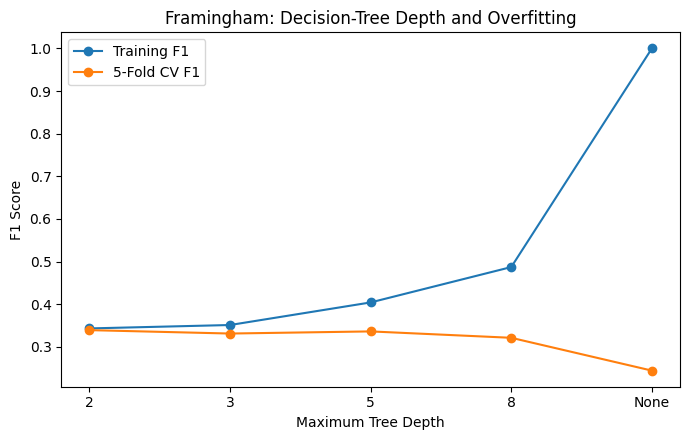

In [20]:
framingham_depth_results = pd.DataFrame({

    "Max Depth": [
        "2",
        "3",
        "5",
        "8",
        "None"
    ],

    "Training F1": [
        0.343,
        0.351,
        0.404,
        0.487,
        1.000
    ],

    "CV F1": [
        0.339,
        0.331,
        0.336,
        0.321,
        0.244
    ]
})


plt.figure(
    figsize=(7, 4.5)
)

plt.plot(
    framingham_depth_results[
        "Max Depth"
    ],
    framingham_depth_results[
        "Training F1"
    ],
    marker="o",
    label="Training F1"
)

plt.plot(
    framingham_depth_results[
        "Max Depth"
    ],
    framingham_depth_results[
        "CV F1"
    ],
    marker="o",
    label="5-Fold CV F1"
)

plt.xlabel(
    "Maximum Tree Depth"
)

plt.ylabel(
    "F1 Score"
)

plt.title(
    "Framingham: Decision-Tree Depth and Overfitting"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "framingham_tree_overfitting.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Framingham PCR and PLSR Component Comparison

Week 3 compared principal component regression and partial least squares regression using cross-validation RMSE.

PLSR reached approximately its best cross-validation performance using substantially fewer components than PCR.

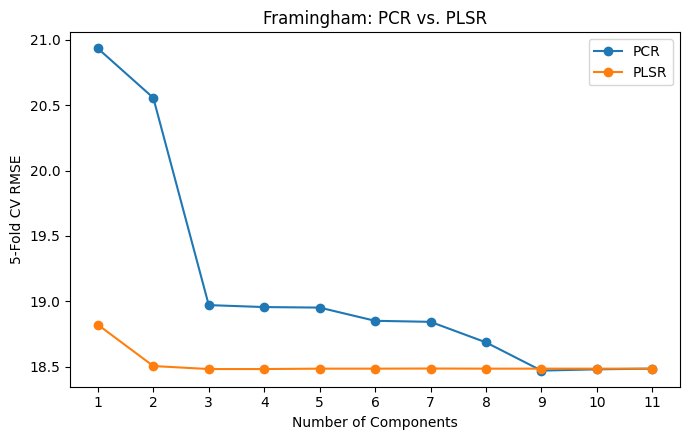

In [21]:
pcr_components = np.arange(
    1,
    12
)

pcr_rmse = [
    20.934,
    20.556,
    18.971,
    18.956,
    18.952,
    18.851,
    18.843,
    18.686,
    18.470,
    18.480,
    18.485
]

plsr_components = np.arange(
    1,
    12
)

plsr_rmse = [
    18.821,
    18.505,
    18.482,
    18.482,
    18.485,
    18.485,
    18.486,
    18.485,
    18.485,
    18.485,
    18.485
]


plt.figure(
    figsize=(7, 4.5)
)

plt.plot(
    pcr_components,
    pcr_rmse,
    marker="o",
    label="PCR"
)

plt.plot(
    plsr_components,
    plsr_rmse,
    marker="o",
    label="PLSR"
)

plt.xlabel(
    "Number of Components"
)

plt.ylabel(
    "5-Fold CV RMSE"
)

plt.title(
    "Framingham: PCR vs. PLSR"
)

plt.xticks(
    range(1, 12)
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "framingham_pcr_plsr.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
classification_results.to_csv(
    "milestone1_final_classification_results.csv",
    index=False
)

threshold_comparison.to_csv(
    "milestone1_threshold_analysis.csv",
    index=False
)

framingham_bootstrap_ci.to_csv(
    "milestone1_framingham_bootstrap_ci.csv",
    index=False
)

paired_differences.to_csv(
    "milestone1_framingham_paired_model_differences.csv",
    index=False
)

heart_bootstrap_ci.to_csv(
    "milestone1_statlog_bootstrap_ci.csv",
    index=False
)

heart_paired_differences.to_csv(
    "milestone1_statlog_paired_model_differences.csv",
    index=False
)

print(
    "All Milestone One analysis tables saved."
)

All Milestone One analysis tables saved.
